# 03 — Feature Analysis
### Spectral, Temporal and Spatial EEG Dynamics Across Attention States

**Project:** EEG Attention State Detection (Focused / Unfocused / Drowsy)

This notebook does **not** train a classifier. Its only question is:

> **What actually changes in the EEG when the attention state changes?**

That matters because it gives notebook 04 (baselines) and notebook 05 (deep learning) a physiological/data-analysis
motivation instead of throwing raw signal at an arbitrary architecture. Concretely, this notebook:

1. loads the cleaned windows from notebook 02 (`windows.csv` + `continuous/*.npz`),
2. computes spectral (band power, absolute + relative), temporal (Hjorth, RMS, line length, ...) and ratio
   (theta/beta, ...) features, per channel and per window,
3. looks at class differences with plots, a topography sketch, Kruskal-Wallis tests, a correlation matrix and PCA,
4. saves one row per window to `data/processed/eeg_features.csv`.

### Inherited caveats (from notebook 02 — still true here)

- **Labels are protocol-derived**, not verified per participant (first ~10 min focused, next ~10 min unfocused,
  remainder drowsy). Treat class differences as differences between *protocol phases*, not confirmed mental states.
- **The 34 → 5 recordings-to-subjects mapping is still unresolved.** `group` = recording, so anything that looks
  like a "subject effect" below is really a *recording* effect (which may or may not correspond to a person).
  This is exactly why we also do a PCA colored by recording, not just by label.
- Windows from the same recording are not independent samples. The Kruskal-Wallis tests here are **exploratory**,
  not a substitute for a properly aggregated statistical test.

## 0. Imports

In [1]:
import json
import itertools
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import welch
from scipy.stats import kruskal
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(x, **kwargs):
        return x

plt.rcParams["figure.figsize"] = (14, 4)
pd.set_option("display.max_columns", 60)

# numpy >= 2.0 renamed trapz -> trapezoid; this works on old and new numpy alike.
_trapz = getattr(np, "trapezoid", None) or np.trapz

c:\Users\gaida\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Configuration

Loads the exact parameters notebook 02 used (`preprocessing_config.json`), so band edges, window length and the
active-channel list can never silently drift out of sync between notebooks.

In [2]:
PROJECT_ROOT = Path("..").resolve()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
CONT_DIR = PROCESSED_DIR / "continuous"
INTERIM_DIR = PROJECT_ROOT / "data" / "interim"

with open(PROCESSED_DIR / "preprocessing_config.json") as f:
    PP_CONFIG = json.load(f)

ACTIVE_CHANNELS = PP_CONFIG["active_channels"]
FS = PP_CONFIG["fs"]
WIN_SEC = PP_CONFIG["win_sec"]
LABEL_NAMES = {int(k): v for k, v in PP_CONFIG["label_names"].items()}
WIN_SAMPLES = int(round(WIN_SEC * FS))

print(f"Active channels ({len(ACTIVE_CHANNELS)}): {ACTIVE_CHANNELS}")
print(f"fs = {FS} Hz, window = {WIN_SEC}s = {WIN_SAMPLES} samples")
print(f"Labels: {LABEL_NAMES}")

# EEG frequency bands. 45 Hz upper edge matches the notebook-02 low-pass filter — band power above
# that frequency would just reflect the filter roll-off, not brain activity.
BANDS = {
    "delta": (1, 4),
    "theta": (4, 8),
    "alpha": (8, 13),
    "beta": (13, 30),
    "gamma": (30, 45),
}
TOTAL_BAND = (1, 45)

LABEL_ORDER = ["focused", "unfocused", "drowsy"]      # fixed order for consistent plots/tables
PALETTE = {"focused": "#1f77b4", "unfocused": "#ff7f0e", "drowsy": "#2ca02c"}

RANDOM_SEED = 42

Active channels (14): ['AF3', 'F7', 'F3', 'FC5', 'T7', 'P7', 'O1', 'O2', 'P8', 'T8', 'FC6', 'F4', 'F8', 'AF4']
fs = 128 Hz, window = 2.0s = 256 samples
Labels: {0: 'focused', 1: 'unfocused', 2: 'drowsy'}


## 2. Load kept windows and verify

`windows.csv` has one row per candidate window (kept and rejected). We only ever use `keep == True` rows here —
rejected windows (artifacts, flat channels, label-boundary straddling, edge effects, packet gaps) were already
screened out in notebook 02.

In [3]:
windows = pd.read_csv(PROCESSED_DIR / "windows.csv")
windows = windows[windows["keep"]].reset_index(drop=True)
windows["label_name"] = windows["label"].map(LABEL_NAMES)

print(f"Kept windows: {len(windows):,}")
print(f"Recordings:   {windows['recording'].nunique()}")
print(f"Channels:     {len(ACTIVE_CHANNELS)}  ({ACTIVE_CHANNELS})")
print(f"Window length: {WIN_SEC}s")
print()
print("Class distribution:")
print(windows["label_name"].value_counts().reindex(LABEL_ORDER).to_string())
print()
print("Windows per recording (head):")
print(windows.groupby("recording").size().head().to_string())

Kept windows: 47,354
Recordings:   34
Channels:     14  (['AF3', 'F7', 'F3', 'FC5', 'T7', 'P7', 'O1', 'O2', 'P8', 'T8', 'FC6', 'F4', 'F8', 'AF4'])
Window length: 2.0s

Class distribution:
label_name
focused       7765
unfocused    10706
drowsy       28883

Windows per recording (head):
recording
eeg_record1.mat     2154
eeg_record10.mat    2519
eeg_record11.mat     107
eeg_record12.mat     339
eeg_record13.mat    1912


In [4]:
# Sanity check: every recording referenced in windows.csv must have a matching .npz, with the same channel order.
missing = [r for r in windows["recording"].unique() if not (CONT_DIR / Path(r).with_suffix(".npz").name).exists()]
assert not missing, f"Missing .npz for: {missing}"

ref_channels = None
for r in windows["recording"].unique():
    chans = list(np.load(CONT_DIR / Path(r).with_suffix(".npz").name)["channels"])
    if ref_channels is None:
        ref_channels = chans
    assert chans == ref_channels, f"{r} has channel order {chans}, expected {ref_channels}"
print("All recordings agree on channel order:", ref_channels)

All recordings agree on channel order: [np.str_('AF3'), np.str_('F7'), np.str_('F3'), np.str_('FC5'), np.str_('T7'), np.str_('P7'), np.str_('O1'), np.str_('O2'), np.str_('P8'), np.str_('T8'), np.str_('FC6'), np.str_('F4'), np.str_('F8'), np.str_('AF4')]


## 3. Spectral features: absolute and relative band power

For every window we take the (already filtered, robust-scaled) segment and compute one Welch PSD per channel, then
integrate it over each band:

$$ P_{band} = \int_{f_1}^{f_2} PSD(f)\, df \qquad\qquad RelativePower_{band} = \frac{P_{band}}{P_{1-45\,Hz}} $$

**Relative power matters here**: because scaling in notebook 02 is per-recording, absolute power is not directly
comparable across recordings, but relative power (a *ratio* within the same window) mostly cancels that out.

We keep both, since exploratory work later may still want absolute levels, but relative power is the one to trust
for cross-recording comparisons.

Each recording is processed once: we gather all its kept windows into a single `(n_windows, win, n_channels)` array
and run `welch` vectorized over that whole batch (`axis=1`), rather than looping window by window in Python.

In [5]:
def band_power_table(recording_name: str, win_starts: np.ndarray) -> pd.DataFrame:
    npz = np.load(CONT_DIR / Path(recording_name).with_suffix(".npz").name)
    signal = npz["signal"]                                    # (n_samples, n_channels)

    idx = win_starts[:, None] + np.arange(WIN_SAMPLES)[None, :]
    seg = signal[idx]                                          # (n_windows, win, n_channels)

    freqs, psd = welch(seg, fs=FS, nperseg=WIN_SAMPLES, axis=1)  # psd: (n_windows, n_freq, n_channels)

    lo, hi = TOTAL_BAND
    total_mask = (freqs >= lo) & (freqs < hi)
    total_power = _trapz(psd[:, total_mask, :], freqs[total_mask], axis=1)   # (n_windows, n_channels)
    total_power = np.maximum(total_power, 1e-12)                              # avoid /0 on a dead channel

    out = {}
    for band, (lo, hi) in BANDS.items():
        mask = (freqs >= lo) & (freqs < hi)
        bp = _trapz(psd[:, mask, :], freqs[mask], axis=1)     # (n_windows, n_channels)
        for c, ch in enumerate(ACTIVE_CHANNELS):
            out[f"{ch}_{band}_abs"] = bp[:, c]
            out[f"{ch}_{band}_rel"] = bp[:, c] / total_power[:, c]
    return pd.DataFrame(out), seg

In [6]:
spectral_frames = []
seg_cache = {}     # keep the raw window segments too, section 7 (temporal features) reuses them

for rec, group in tqdm(windows.groupby("recording", sort=False), desc="Spectral features"):
    starts = group["start"].to_numpy()
    feats, seg = band_power_table(rec, starts)
    feats.index = group.index
    spectral_frames.append(feats)
    seg_cache[rec] = (group.index.to_numpy(), seg)

spectral = pd.concat(spectral_frames).sort_index()
print(f"Spectral features: {spectral.shape[1]} columns "
      f"({len(ACTIVE_CHANNELS)} channels x {len(BANDS)} bands x 2 [abs, rel])")
spectral.head()

Spectral features: 100%|██████████| 34/34 [00:10<00:00,  3.26it/s]

Spectral features: 140 columns (14 channels x 5 bands x 2 [abs, rel])


,AF3_delta_abs,AF3_delta_rel,F7_delta_abs,F7_delta_rel,F3_delta_abs,F3_delta_rel,FC5_delta_abs,FC5_delta_rel,T7_delta_abs,T7_delta_rel,P7_delta_abs,P7_delta_rel,O1_delta_abs,O1_delta_rel,O2_delta_abs,O2_delta_rel,P8_delta_abs,P8_delta_rel,T8_delta_abs,T8_delta_rel,FC6_delta_abs,FC6_delta_rel,F4_delta_abs,F4_delta_rel,F8_delta_abs,F8_delta_rel,AF4_delta_abs,AF4_delta_rel,AF3_theta_abs,AF3_theta_rel,...,AF4_beta_abs,AF4_beta_rel,AF3_gamma_abs,AF3_gamma_rel,F7_gamma_abs,F7_gamma_rel,F3_gamma_abs,F3_gamma_rel,FC5_gamma_abs,FC5_gamma_rel,T7_gamma_abs,T7_gamma_rel,P7_gamma_abs,P7_gamma_rel,O1_gamma_abs,O1_gamma_rel,O2_gamma_abs,O2_gamma_rel,P8_gamma_abs,P8_gamma_rel,T8_gamma_abs,T8_gamma_rel,FC6_gamma_abs,FC6_gamma_rel,F4_gamma_abs,F4_gamma_rel,F8_gamma_abs,F8_gamma_rel,AF4_gamma_abs,AF4_gamma_rel
0,0.128535,0.115053,2.840549,0.809264,0.953905,0.668202,0.064938,0.070100,0.062889,0.078129,0.321837,0.537000,5.985093,0.851332,4.309412,0.830542,0.499303,0.487484,0.071523,0.109927,0.022663,0.029411,0.104339,0.084298,4.380753,0.302643,1.741519,0.691198,0.142266,0.127344,...,0.189944,0.075388,0.359579,0.321864,0.030458,0.008677,0.044462,0.031145,0.343011,0.370281,0.290820,0.361297,0.022163,0.036980,0.051792,0.007367,0.036519,0.007038,0.040433,0.039476,0.104878,0.161193,0.144544,0.187582,0.331035,0.267450,3.631369,0.250872,0.057830,0.022952
1,0.026466,0.032581,0.332922,0.361033,0.378021,0.285438,0.039500,0.025588,0.032201,0.057406,5.955489,0.816261,0.445229,0.411691,0.306652,0.365626,0.437051,0.371954,0.053728,0.090850,0.009736,0.010662,0.483405,0.275749,0.494577,0.068918,0.454961,0.404388,0.118979,0.146470,...,0.195810,0.174044,0.232092,0.285720,0.034880,0.037825,0.034530,0.026073,0.624989,0.404868,0.257319,0.458727,0.040728,0.005582,0.057196,0.052887,0.038137,0.045471,0.029985,0.025519,0.163561,0.276569,0.097184,0.106424,0.326424,0.186202,2.006043,0.279537,0.050234,0.044650
2,0.102476,0.116663,0.259596,0.325872,0.415012,0.501951,0.058914,0.039695,0.080219,0.087711,1.591600,0.692035,0.251801,0.358094,0.137867,0.264766,0.433750,0.507421,0.144253,0.179418,0.033084,0.025090,0.737803,0.314708,1.098944,0.143480,0.182468,0.258975,0.074268,0.084549,...,0.176060,0.249880,0.344681,0.392398,0.056273,0.070640,0.070062,0.084739,0.477728,0.321885,0.284830,0.311431,0.039251,0.017066,0.081295,0.115612,0.062099,0.119258,0.055918,0.065415,0.122367,0.152197,0.141160,0.107055,0.342017,0.145887,2.055589,0.268381,0.074777,0.106130
3,0.104127,0.123614,0.141284,0.197159,0.226009,0.296224,0.040277,0.043646,0.032640,0.053910,2.404139,0.764602,0.199445,0.295342,0.148114,0.307234,0.168341,0.332961,0.029503,0.046506,0.095769,0.057572,0.270079,0.107570,1.396642,0.108374,0.245390,0.303017,0.055193,0.065521,...,0.205489,0.253745,0.227539,0.270121,0.027079,0.037788,0.044304,0.058069,0.292862,0.317361,0.167272,0.276273,0.036708,0.011674,0.044900,0.066489,0.024792,0.051427,0.023555,0.046589,0.127781,0.201418,0.098793,0.059391,0.964418,0.384119,4.043630,0.313770,0.043024,0.053128
4,0.090601,0.060645,0.063226,0.106129,0.237151,0.360259,0.119378,0.105760,0.077551,0.098458,0.672750,0.605532,0.582767,0.537883,0.086069,0.166740,0.220133,0.309051,0.143923,0.170085,0.071419,0.048244,0.266607,0.129847,3.159781,0.226200,0.322118,0.392136,0.040335,0.026998,...,0.120216,0.146347,0.582850,0.390135,0.035777,0.060053,0.036837,0.055960,0.409186,0.362506,0.292646,0.371539,0.055435,0.049896,0.046027,0.042482,0.030387,0.058869,0.031182,0.043776,0.143922,0.170085,0.075939,0.051296,0.466155,0.227034,1.841779,0.131848,0.049870,0.060710


## 4. Global (channel-averaged) band power

Per-channel features are useful for topography and for the model later, but for readable plots and statistics we
also want one number per band per window: the mean across channels.

In [7]:
global_rel = pd.DataFrame({
    f"global_{band}": spectral[[f"{ch}_{band}_rel" for ch in ACTIVE_CHANNELS]].mean(axis=1)
    for band in BANDS
})
global_abs = pd.DataFrame({
    f"global_{band}_abs": spectral[[f"{ch}_{band}_abs" for ch in ACTIVE_CHANNELS]].mean(axis=1)
    for band in BANDS
})
global_feats = pd.concat([global_rel, global_abs], axis=1)
global_feats.head()

,global_delta,global_theta,global_alpha,global_beta,global_gamma,global_delta_abs,global_theta_abs,global_alpha_abs,global_beta_abs,global_gamma_abs
0,0.404613,0.100640,0.104904,0.173129,0.148155,1.534804,0.241133,0.255808,0.373289,0.392064
1,0.255582,0.174930,0.161290,0.204772,0.159718,0.674996,0.267869,0.242400,0.382584,0.285236
2,0.272563,0.137591,0.146655,0.215433,0.162721,0.394842,0.182872,0.237000,0.360573,0.300575
3,0.216981,0.158541,0.134662,0.249832,0.153401,0.392983,0.253204,0.353280,0.386822,0.440476
4,0.236926,0.186185,0.124815,0.242234,0.148299,0.436677,0.328147,0.312124,0.463316,0.292714


C:\Users\gaida\AppData\Local\Temp\ipykernel_21468\340328062.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_by_class, labels=LABEL_ORDER, showfliers=False, patch_artist=True)
C:\Users\gaida\AppData\Local\Temp\ipykernel_21468\340328062.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_by_class, labels=LABEL_ORDER, showfliers=False, patch_artist=True)
C:\Users\gaida\AppData\Local\Temp\ipykernel_21468\340328062.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_by_class, labels=LABEL_ORDER, showfliers=False, patch_artist=True)
C:\Users\gaida\AppData\Lo

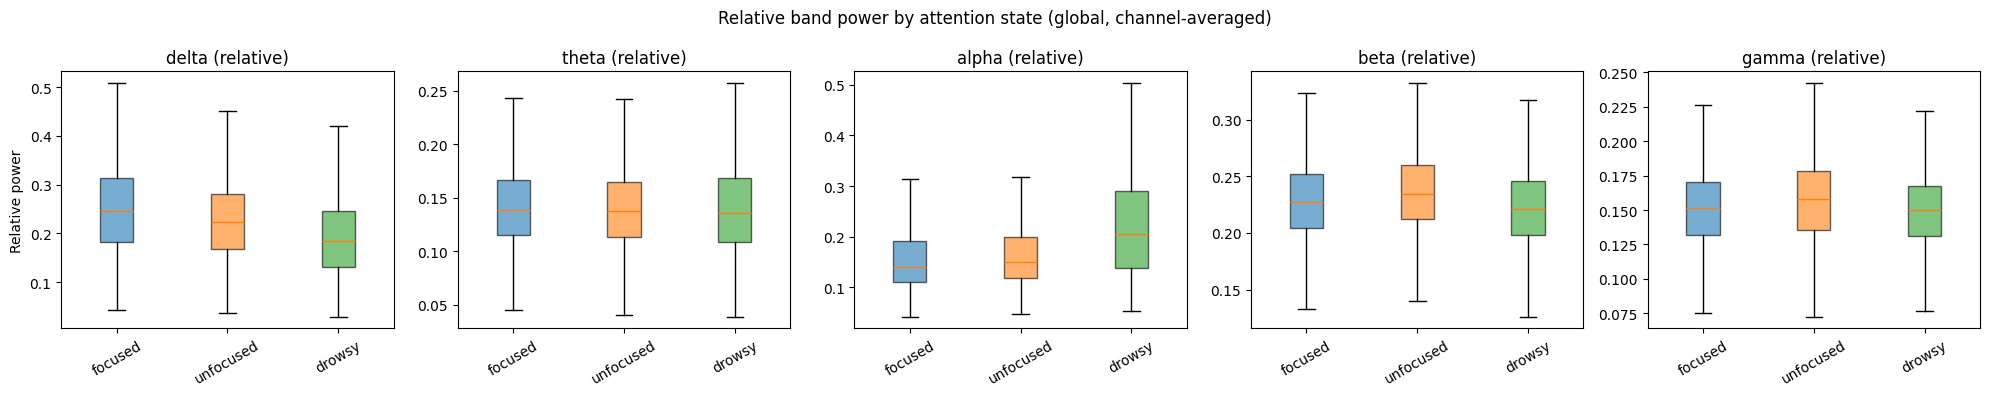

In [8]:
plot_df = windows[["label_name"]].join(global_rel)

fig, axes = plt.subplots(1, len(BANDS), figsize=(4 * len(BANDS), 4), sharey=False)
for ax, band in zip(axes, BANDS):
    data_by_class = [plot_df.loc[plot_df.label_name == lab, f"global_{band}"] for lab in LABEL_ORDER]
    bp = ax.boxplot(data_by_class, labels=LABEL_ORDER, showfliers=False, patch_artist=True)
    for patch, lab in zip(bp["boxes"], LABEL_ORDER):
        patch.set_facecolor(PALETTE[lab])
        patch.set_alpha(0.6)
    ax.set_title(f"{band} (relative)")
    ax.tick_params(axis="x", rotation=30)
axes[0].set_ylabel("Relative power")
plt.suptitle("Relative band power by attention state (global, channel-averaged)")
plt.tight_layout()
plt.show()

> Read the boxplots before assuming a direction. A common expectation in drowsiness research is higher
> theta/delta and lower beta during drowsiness, but that is a hypothesis to check against *this* dataset and this
> protocol-derived labeling, not something to assume.

## 5. Band-power topography

A schematic (not anatomically exact) layout of the 14 Emotiv EPOC electrodes, colored by mean relative power per
class. This uses only the channels notebook 02 kept as active — if some electrodes were dropped, they will simply
be missing from the plot.

For a publication-quality scalp topomap (interpolated, anatomically correct) this could later be redone with
`mne.viz.plot_topomap`, using a standard montage. Here we keep it dependency-light.

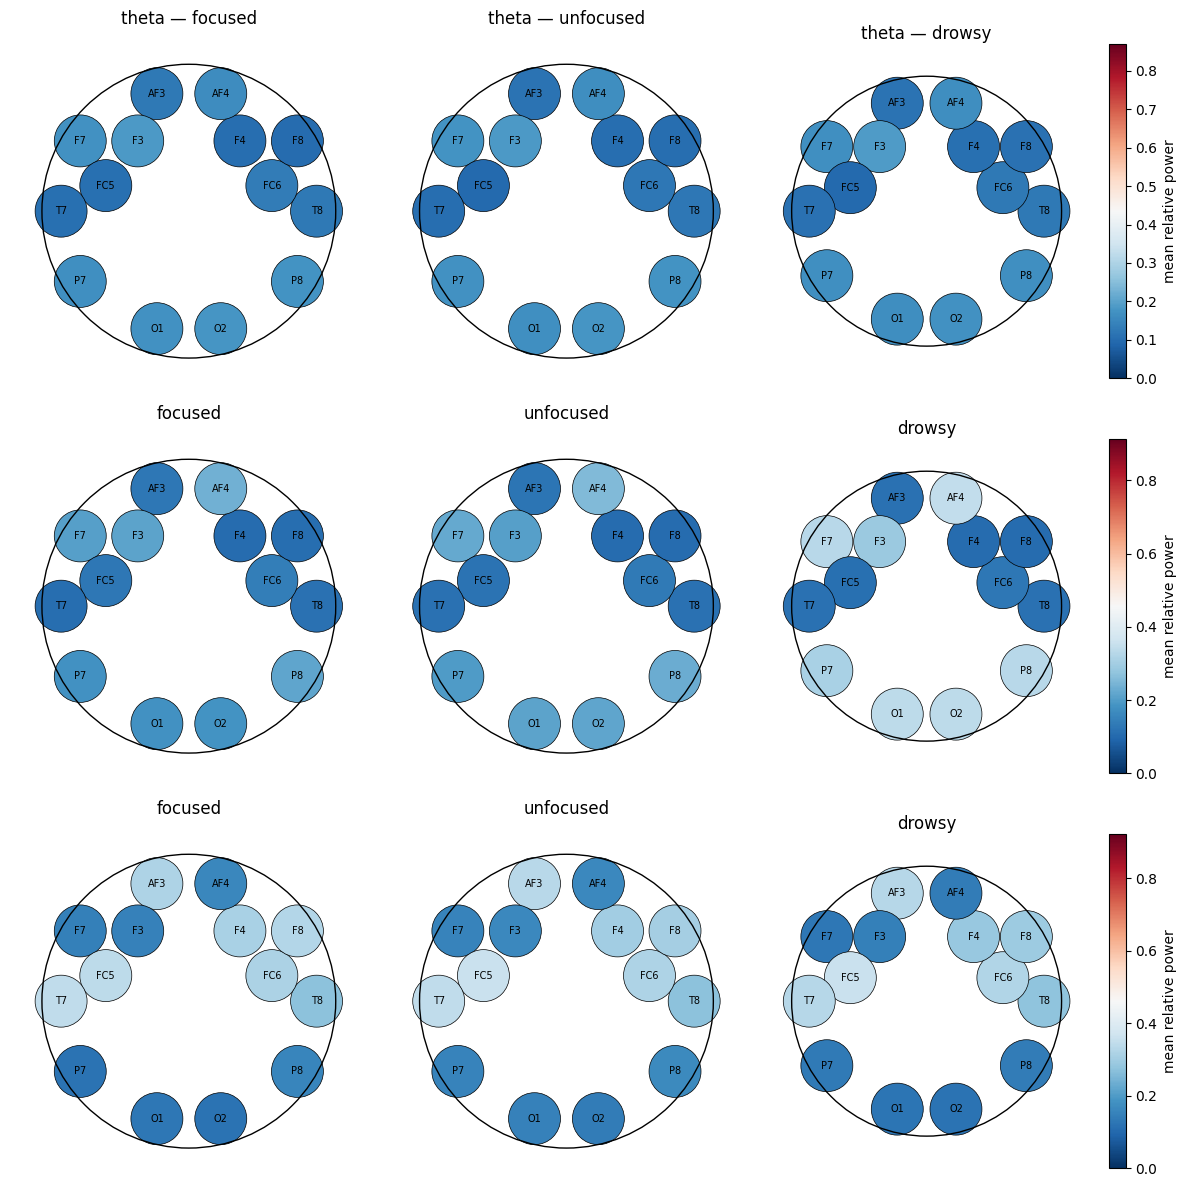

In [9]:
# Approximate 10-20-style positions (top-down view, nose points up), good enough for a schematic comparison
ELECTRODE_POS = {
    "AF3": (-0.25, 0.92), "AF4": (0.25, 0.92),
    "F7": (-0.85, 0.55), "F3": (-0.40, 0.55), "F4": (0.40, 0.55), "F8": (0.85, 0.55),
    "FC5": (-0.65, 0.20), "FC6": (0.65, 0.20),
    "T7": (-1.00, 0.00), "T8": (1.00, 0.00),
    "P7": (-0.85, -0.55), "P8": (0.85, -0.55),
    "O1": (-0.25, -0.92), "O2": (0.25, -0.92),
}
plotted_channels = [c for c in ACTIVE_CHANNELS if c in ELECTRODE_POS]
missing_pos = [c for c in ACTIVE_CHANNELS if c not in ELECTRODE_POS]
if missing_pos:
    print(f"No plotting position for: {missing_pos} (skipped in the topography plot only)")


def topography_grid(bands_to_show):
    fig, axes = plt.subplots(len(bands_to_show), len(LABEL_ORDER),
                              figsize=(4 * len(LABEL_ORDER), 4 * len(bands_to_show)))
    axes = np.atleast_2d(axes)

    # shared color scale per band row, so the three classes are visually comparable
    for r, band in enumerate(bands_to_show):
        cols = [f"{ch}_{band}_rel" for ch in plotted_channels]
        vmin = spectral[cols].min().min()
        vmax = spectral[cols].max().max()
        for c, lab in enumerate(LABEL_ORDER):
            ax = axes[r, c]
            mask = windows["label_name"] == lab
            vals = spectral.loc[mask, cols].mean(axis=0).values
            xs = [ELECTRODE_POS[ch][0] for ch in plotted_channels]
            ys = [ELECTRODE_POS[ch][1] for ch in plotted_channels]
            sca = ax.scatter(xs, ys, c=vals, s=1400, cmap="RdBu_r", vmin=vmin, vmax=vmax,
                              edgecolors="k", linewidths=0.5)
            for ch, x, y in zip(plotted_channels, xs, ys):
                ax.annotate(ch, (x, y), ha="center", va="center", fontsize=7)
            circle = plt.Circle((0, 0), 1.15, fill=False, lw=1)
            ax.add_patch(circle)
            ax.set_xlim(-1.4, 1.4); ax.set_ylim(-1.4, 1.4)
            ax.set_aspect("equal"); ax.axis("off")
            ax.set_title(f"{band} — {lab}" if r == 0 else lab)
            if c == len(LABEL_ORDER) - 1:
                plt.colorbar(sca, ax=ax, fraction=0.046, label="mean relative power")
    plt.tight_layout()
    plt.show()


topography_grid(["theta", "alpha", "beta"])

## 6. EEG ratios

Theta/beta ratio (TBR) and related ratios are common candidate markers of attention/vigilance in the EEG
literature. We compute them **globally first** (channel-averaged power), and only break them out per channel if the
global version already looks informative — adding 14x more near-duplicate columns before checking that is not
worth the redundancy it creates (see the correlation matrix in section 9).

C:\Users\gaida\AppData\Local\Temp\ipykernel_21468\945071514.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_by_class, labels=LABEL_ORDER, showfliers=False, patch_artist=True)
C:\Users\gaida\AppData\Local\Temp\ipykernel_21468\945071514.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_by_class, labels=LABEL_ORDER, showfliers=False, patch_artist=True)
C:\Users\gaida\AppData\Local\Temp\ipykernel_21468\945071514.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_by_class, labels=LABEL_ORDER, showfliers=False, patch_artist=True)


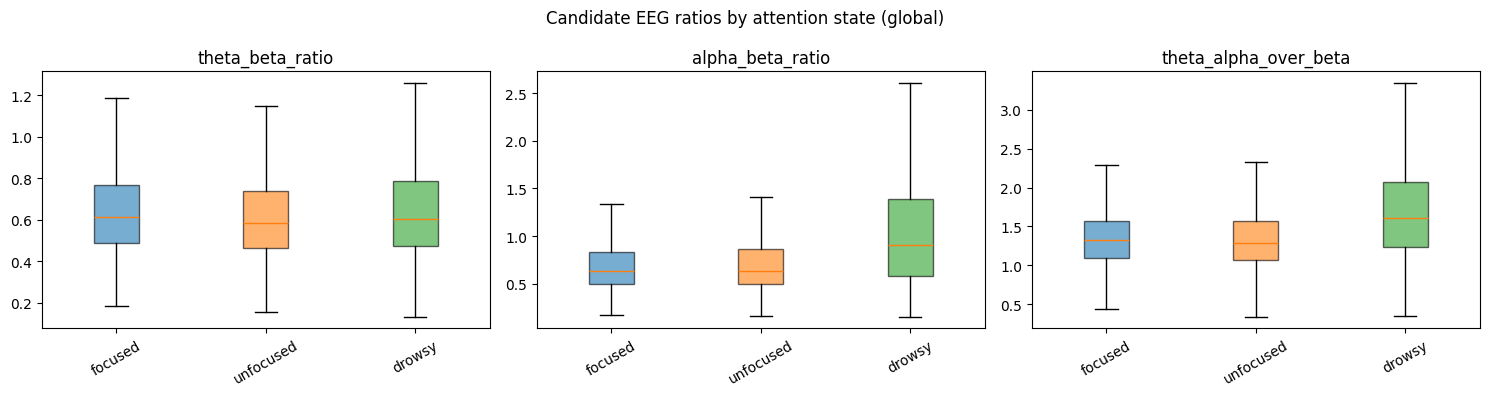

In [10]:
eps = 1e-12
ratios = pd.DataFrame({
    "theta_beta_ratio": global_rel["global_theta"] / (global_rel["global_beta"] + eps),
    "alpha_beta_ratio": global_rel["global_alpha"] / (global_rel["global_beta"] + eps),
    "theta_alpha_over_beta": (global_rel["global_theta"] + global_rel["global_alpha"])
                              / (global_rel["global_beta"] + eps),
})

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ratios.columns):
    data_by_class = [ratios.loc[windows.label_name == lab, col] for lab in LABEL_ORDER]
    bp = ax.boxplot(data_by_class, labels=LABEL_ORDER, showfliers=False, patch_artist=True)
    for patch, lab in zip(bp["boxes"], LABEL_ORDER):
        patch.set_facecolor(PALETTE[lab]); patch.set_alpha(0.6)
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=30)
plt.suptitle("Candidate EEG ratios by attention state (global)")
plt.tight_layout()
plt.show()

## 7. Temporal (time-domain) features

Since this project is about EEG *dynamics*, not just spectral content, we add a compact set of time-domain
features per channel, reusing the raw window segments already gathered in section 3 (`seg_cache`), so the signal is
not read from disk twice:

- **mean, std, RMS, peak-to-peak** — basic amplitude descriptors,
- **line length** — sum of absolute first differences, sensitive to how "busy" the signal is,
- **zero-crossing rate** — how often the (mean-centered) signal changes sign,
- **Hjorth activity, mobility, complexity** — the standard EEG time-domain triplet:

$$ Activity = Var(x) \qquad Mobility = \sqrt{\frac{Var(x')}{Var(x)}} \qquad Complexity = \frac{Mobility(x')}{Mobility(x)} $$

In [11]:
def hjorth(seg):
    """seg: (n_windows, win, n_channels). Returns activity, mobility, complexity, each (n_windows, n_channels)."""
    d1 = np.diff(seg, axis=1)
    d2 = np.diff(d1, axis=1)

    var0 = seg.var(axis=1)
    var1 = d1.var(axis=1)
    var2 = d2.var(axis=1)

    activity = var0
    mobility = np.sqrt(np.maximum(var1, 0) / (var0 + 1e-12))
    mobility_d1 = np.sqrt(np.maximum(var2, 0) / (var1 + 1e-12))
    complexity = mobility_d1 / (mobility + 1e-12)
    return activity, mobility, complexity


def temporal_feature_table(seg):
    """seg: (n_windows, win, n_channels) -> DataFrame indexed 0..n_windows-1."""
    mean = seg.mean(axis=1)
    std = seg.std(axis=1)
    rms = np.sqrt((seg ** 2).mean(axis=1))
    ptp = seg.max(axis=1) - seg.min(axis=1)
    line_length = np.abs(np.diff(seg, axis=1)).sum(axis=1)
    centered = seg - mean[:, None, :]
    zcr = (np.diff(np.sign(centered), axis=1) != 0).mean(axis=1)
    activity, mobility, complexity = hjorth(seg)

    out = {}
    for c, ch in enumerate(ACTIVE_CHANNELS):
        out[f"{ch}_mean"] = mean[:, c]
        out[f"{ch}_std"] = std[:, c]
        out[f"{ch}_rms"] = rms[:, c]
        out[f"{ch}_ptp"] = ptp[:, c]
        out[f"{ch}_line_length"] = line_length[:, c]
        out[f"{ch}_zcr"] = zcr[:, c]
        out[f"{ch}_hjorth_activity"] = activity[:, c]
        out[f"{ch}_hjorth_mobility"] = mobility[:, c]
        out[f"{ch}_hjorth_complexity"] = complexity[:, c]
    return out

In [12]:
temporal_frames = []
for rec, (row_idx, seg) in tqdm(seg_cache.items(), desc="Temporal features"):
    feats = pd.DataFrame(temporal_feature_table(seg), index=row_idx)
    temporal_frames.append(feats)

temporal = pd.concat(temporal_frames).sort_index()
print(f"Temporal features: {temporal.shape[1]} columns ({len(ACTIVE_CHANNELS)} channels x 9 descriptors)")
temporal.head()

Temporal features: 100%|██████████| 34/34 [00:05<00:00,  6.32it/s]

Temporal features: 126 columns (14 channels x 9 descriptors)


,AF3_mean,AF3_std,AF3_rms,AF3_ptp,AF3_line_length,AF3_zcr,AF3_hjorth_activity,AF3_hjorth_mobility,AF3_hjorth_complexity,F7_mean,F7_std,F7_rms,F7_ptp,F7_line_length,F7_zcr,F7_hjorth_activity,F7_hjorth_mobility,F7_hjorth_complexity,F3_mean,F3_std,F3_rms,F3_ptp,F3_line_length,F3_zcr,F3_hjorth_activity,F3_hjorth_mobility,F3_hjorth_complexity,FC5_mean,FC5_std,FC5_rms,...,FC6_hjorth_activity,FC6_hjorth_mobility,FC6_hjorth_complexity,F4_mean,F4_std,F4_rms,F4_ptp,F4_line_length,F4_zcr,F4_hjorth_activity,F4_hjorth_mobility,F4_hjorth_complexity,F8_mean,F8_std,F8_rms,F8_ptp,F8_line_length,F8_zcr,F8_hjorth_activity,F8_hjorth_mobility,F8_hjorth_complexity,AF4_mean,AF4_std,AF4_rms,AF4_ptp,AF4_line_length,AF4_zcr,AF4_hjorth_activity,AF4_hjorth_mobility,AF4_hjorth_complexity
0,-0.034597,0.995839,0.996439,6.532301,215.495483,0.364706,0.991694,1.129538,1.255932,0.631525,2.092839,2.186046,9.203527,101.714127,0.062745,4.379973,0.241875,4.607359,0.673673,1.998821,2.109294,9.735955,102.760239,0.078431,3.995287,0.261135,4.352368,-0.065664,1.053849,1.055893,...,0.746338,0.913695,1.517785,0.004188,1.134688,1.134695,6.857946,224.333984,0.321569,1.287516,1.000190,1.379214,0.281521,3.931593,3.941659,24.156303,641.702209,0.329412,15.457426,0.930996,1.518701,0.626553,2.174458,2.262925,9.903434,133.708771,0.121569,4.728265,0.307371,3.955495
1,-0.038454,0.920708,0.921511,5.641240,196.518158,0.321569,0.847704,1.059899,1.347670,0.091513,1.812105,1.814415,10.916954,103.707314,0.137255,3.283726,0.290014,3.972775,0.092870,2.028011,2.030137,12.334102,116.628807,0.117647,4.112828,0.279366,4.169224,-0.034752,1.226142,1.226634,...,1.083483,0.772358,1.545861,0.009783,1.414878,1.414912,8.074998,220.999893,0.219608,2.001881,0.841533,1.633687,0.258965,3.240225,3.250556,20.305801,521.301819,0.301961,10.499056,0.935886,1.448481,0.040439,2.129216,2.129599,12.351381,134.311447,0.156863,4.533559,0.309679,3.957912
2,-0.008864,0.937552,0.937594,5.945208,197.930817,0.376471,0.879004,1.070740,1.308572,-0.008590,0.911540,0.911580,4.887739,102.868301,0.184314,0.830905,0.567686,2.079065,-0.027866,1.017118,1.017499,5.222173,113.033188,0.172549,1.034528,0.554386,2.195410,-0.031893,1.162295,1.162732,...,0.958749,0.778680,1.613904,0.088496,1.587408,1.589873,7.849946,256.416382,0.211765,2.519863,0.882779,1.597304,-0.022555,3.081638,3.081721,23.129272,527.130676,0.376471,9.496495,0.997449,1.394315,-0.058866,0.986985,0.988739,5.416426,124.531105,0.180392,0.974140,0.638940,1.872693
3,-0.057564,1.004513,1.006161,6.368497,207.357239,0.380392,1.009046,1.065078,1.269009,-0.003112,0.864773,0.864778,4.432878,97.636314,0.192157,0.747832,0.562191,1.983928,-0.050201,0.920473,0.921841,5.869004,105.314804,0.188235,0.847271,0.575199,2.016592,-0.060874,0.994144,0.996006,...,1.592271,0.622348,1.804270,0.087364,1.524192,1.526694,8.072371,291.629517,0.282353,2.323161,0.969820,1.430422,-0.015112,3.548264,3.548297,23.129272,594.507935,0.337255,12.590179,0.966391,1.481769,-0.020082,0.955995,0.956206,6.634900,111.778397,0.180392,0.913927,0.590274,1.962148
4,-0.067087,1.150611,1.152565,6.541007,242.196075,0.349020,1.323906,1.051089,1.295252,-0.033587,0.854242,0.854902,5.111544,96.694298,0.192157,0.729730,0.570898,2.022807,-0.021466,0.853603,0.853873,5.869004,104.886734,0.211765,0.728639,0.616608,1.908559,-0.033179,1.010202,1.010747,...,1.677806,0.643636,1.780128,0.060339,1.391671,1.392979,7.401075,285.439087,0.321569,1.936749,1.024686,1.357379,-0.079592,3.777381,3.778219,19.977207,512.852722,0.192157,14.268605,0.821252,1.672426,-0.022729,0.986805,0.987067,6.634900,123.586739,0.227451,0.973784,0.642422,1.893587


C:\Users\gaida\AppData\Local\Temp\ipykernel_21468\4133721045.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_by_class, labels=LABEL_ORDER, showfliers=False, patch_artist=True)
C:\Users\gaida\AppData\Local\Temp\ipykernel_21468\4133721045.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_by_class, labels=LABEL_ORDER, showfliers=False, patch_artist=True)
C:\Users\gaida\AppData\Local\Temp\ipykernel_21468\4133721045.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_by_class, labels=LABEL_ORDER, showfliers=False, patch_artist=True)


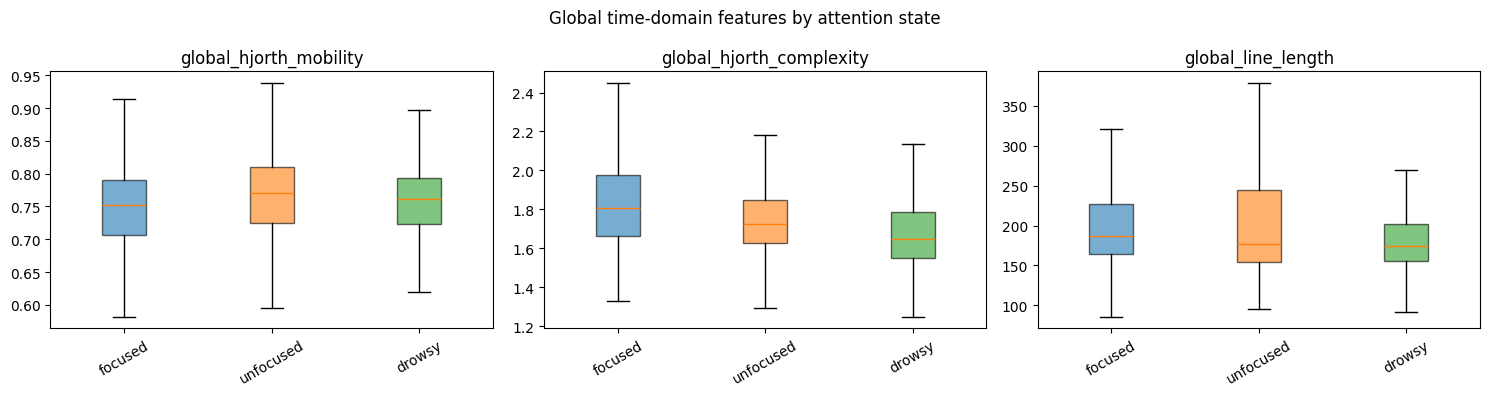

In [13]:
global_temporal = pd.DataFrame({
    "global_hjorth_mobility": temporal[[f"{c}_hjorth_mobility" for c in ACTIVE_CHANNELS]].mean(axis=1),
    "global_hjorth_complexity": temporal[[f"{c}_hjorth_complexity" for c in ACTIVE_CHANNELS]].mean(axis=1),
    "global_line_length": temporal[[f"{c}_line_length" for c in ACTIVE_CHANNELS]].mean(axis=1),
})

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, global_temporal.columns):
    data_by_class = [global_temporal.loc[windows.label_name == lab, col] for lab in LABEL_ORDER]
    bp = ax.boxplot(data_by_class, labels=LABEL_ORDER, showfliers=False, patch_artist=True)
    for patch, lab in zip(bp["boxes"], LABEL_ORDER):
        patch.set_facecolor(PALETTE[lab]); patch.set_alpha(0.6)
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=30)
plt.suptitle("Global time-domain features by attention state")
plt.tight_layout()
plt.show()

## 8. Statistical comparison between states (exploratory)

For each **global** feature we run a Kruskal-Wallis test (a non-parametric alternative to one-way ANOVA — no
Gaussian assumption) across the three classes:

$$ H_0: D_{focused} = D_{unfocused} = D_{drowsy} $$

**Important caveat, stated up front rather than in a footnote:** each window is treated here as one observation,
but windows from the same recording overlap in time and are not independent. A large sample size (thousands of
windows) will make even small, non-meaningful differences look "significant". Read this table as *which features
separate the classes best in this sample*, not as confirmatory inference. A stricter version (one aggregated value
per recording, `n = 34`) is suggested below as a follow-up.

In [14]:
global_all = pd.concat([global_rel, ratios, global_temporal], axis=1)

rows = []
for col in global_all.columns:
    groups = [global_all.loc[windows.label_name == lab, col].dropna() for lab in LABEL_ORDER]
    stat, p = kruskal(*groups)
    rows.append({"feature": col, "H": stat, "p": p})

stats_df = pd.DataFrame(rows).sort_values("H", ascending=False).reset_index(drop=True)
stats_df["significant_p<0.001"] = stats_df["p"] < 0.001
display(stats_df)

,feature,H,p,significant_p<0.001
0,global_alpha,4062.128202,0.000000e+00,True
1,alpha_beta_ratio,4051.862198,0.000000e+00,True
2,theta_alpha_over_beta,3903.567508,0.000000e+00,True
3,global_hjorth_complexity,3494.574082,0.000000e+00,True
4,global_delta,3055.709226,0.000000e+00,True
5,global_beta,1064.612950,6.641025e-232,True
6,global_line_length,809.319111,1.813794e-176,True
7,global_gamma,566.183392,1.134589e-123,True
8,global_hjorth_mobility,494.420268,4.345132e-108,True
9,theta_beta_ratio,107.893043,3.726691e-24,True


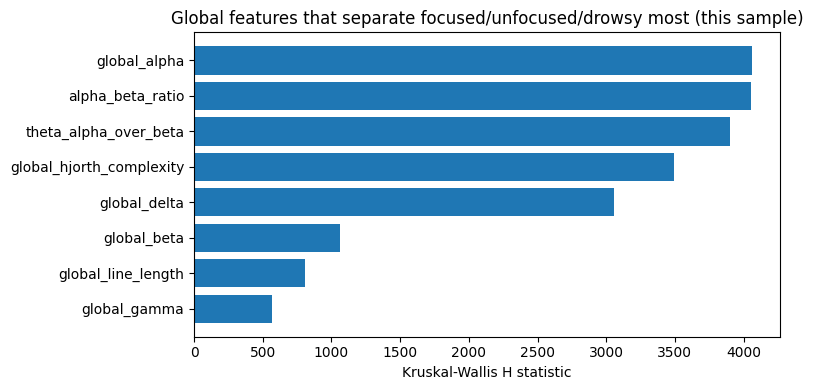

In [15]:
top = stats_df.head(8)
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(top["feature"][::-1], top["H"][::-1])
ax.set_xlabel("Kruskal-Wallis H statistic")
ax.set_title("Global features that separate focused/unfocused/drowsy most (this sample)")
plt.tight_layout()
plt.show()

**Suggested follow-up (not run here):** aggregate each feature to one value per recording (e.g. the median over
that recording's kept windows for a given label) and re-run Kruskal-Wallis with `n = 34` instead of `n = ` (number
of windows). That test would be slower to reach significance but far more defensible, and it sidesteps the
window-independence problem entirely.

## 9. Feature correlation

A correlation matrix of the **global** features tells us which ones are redundant before they go into a model —
for example, absolute and relative power for the same band are expected to correlate strongly with each other and
with a ratio that already uses that band.

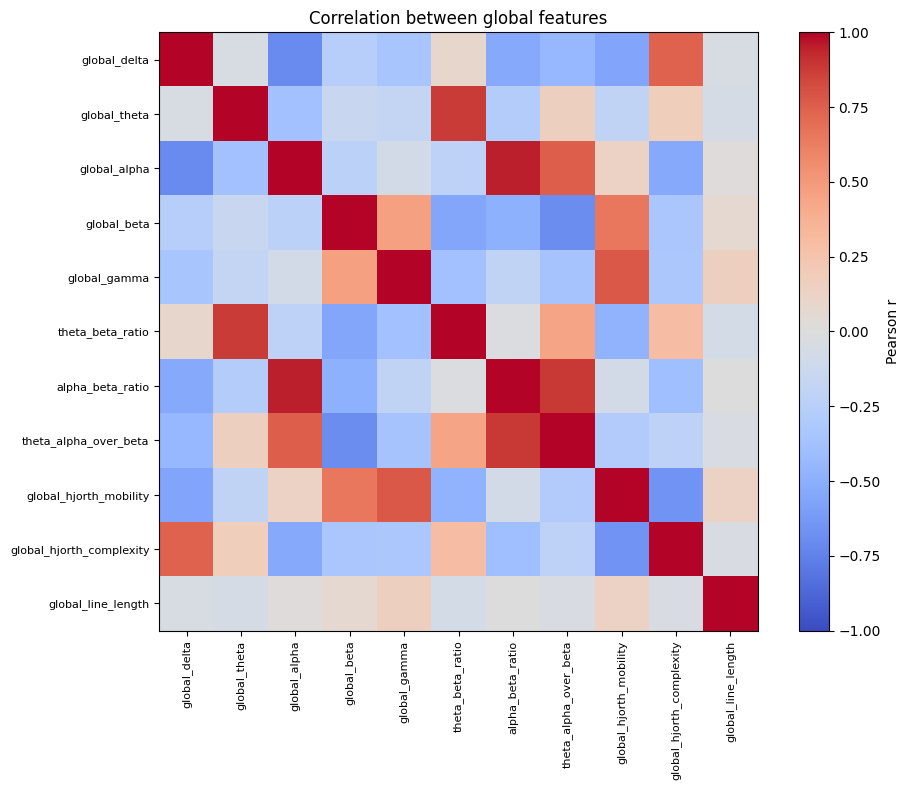

In [16]:
corr = global_all.corr()

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns))); ax.set_xticklabels(corr.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(corr.columns))); ax.set_yticklabels(corr.columns, fontsize=8)
plt.colorbar(im, ax=ax, label="Pearson r")
ax.set_title("Correlation between global features")
plt.tight_layout()
plt.show()

In [17]:
pairs = corr.where(~np.eye(len(corr), dtype=bool)).abs().unstack().sort_values(ascending=False)
pairs = pairs[~pairs.index.duplicated()].head(10)
print("Most correlated feature pairs (|r|):")
for (a, b), r in pairs.items():
    print(f"  {a:28s} <-> {b:28s}  r = {corr.loc[a, b]:+.2f}")

Most correlated feature pairs (|r|):
  global_alpha                 <-> alpha_beta_ratio              r = +0.95
  alpha_beta_ratio             <-> global_alpha                  r = +0.95
  alpha_beta_ratio             <-> theta_alpha_over_beta         r = +0.89
  theta_alpha_over_beta        <-> alpha_beta_ratio              r = +0.89
  theta_beta_ratio             <-> global_theta                  r = +0.88
  global_theta                 <-> theta_beta_ratio              r = +0.88
  global_hjorth_mobility       <-> global_gamma                  r = +0.78
  global_gamma                 <-> global_hjorth_mobility        r = +0.78
  global_alpha                 <-> theta_alpha_over_beta         r = +0.75
  theta_alpha_over_beta        <-> global_alpha                  r = +0.75


## 10. PCA: is there attention-state structure, or is it dominated by recording differences?

Two PCA projections of the same (standardized) global feature set:

- colored by **attention state** — is there any visible structure at all?
- colored by **recording** — could that structure just be "which recording this window came from"?

Once the subject mapping (section 10 of notebook 02) is resolved, add a third plot colored by subject — the
comparison between "colored by recording" and "colored by subject" is what will actually tell us whether a
recording effect is a subject effect.

Explained variance ratio: PC1=33.8%, PC2=32.5%


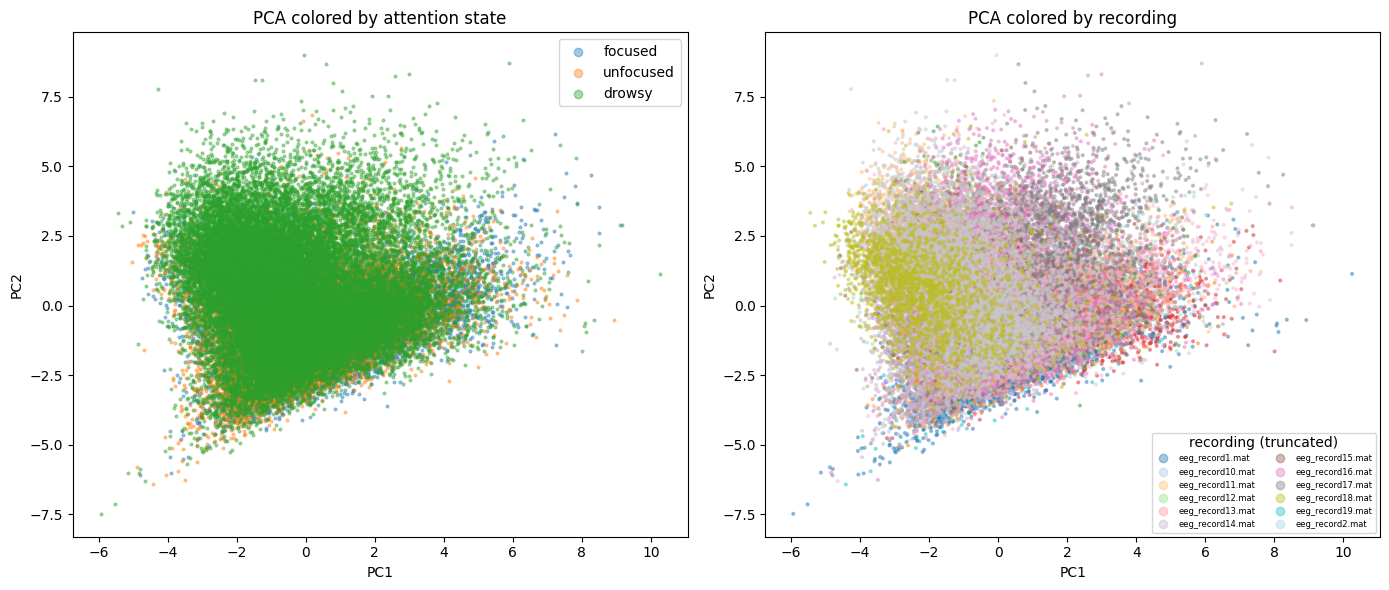

In [18]:
X = StandardScaler().fit_transform(global_all.fillna(global_all.median()))
pca = PCA(n_components=2, random_state=RANDOM_SEED)
pcs = pca.fit_transform(X)
print(f"Explained variance ratio: PC1={pca.explained_variance_ratio_[0]:.1%}, "
      f"PC2={pca.explained_variance_ratio_[1]:.1%}")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for lab in LABEL_ORDER:
    m = windows["label_name"] == lab
    axes[0].scatter(pcs[m, 0], pcs[m, 1], s=4, alpha=0.4, color=PALETTE[lab], label=lab)
axes[0].set_title("PCA colored by attention state")
axes[0].legend(markerscale=3)

recs = windows["recording"].astype("category")
sca = axes[1].scatter(pcs[:, 0], pcs[:, 1], s=4, alpha=0.4, c=recs.cat.codes, cmap="tab20")
axes[1].set_title("PCA colored by recording")
handles, _ = sca.legend_elements(num=min(10, recs.cat.categories.size))
axes[1].legend(handles, list(recs.cat.categories[:len(handles)]), fontsize=6, ncol=2,
               title="recording (truncated)", loc="best")

for ax in axes:
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
plt.tight_layout()
plt.show()

Read this side by side, not in isolation. If the same regions light up in both plots — i.e. state and recording
are confounded in feature space — any classifier evaluated by randomly splitting windows will look better than it
really is, because it can partly learn "which recording" instead of "which attention state". That is precisely why
notebook 04 must evaluate by recording (or, once available, by subject), never by randomly splitting windows.

## 11. Save features

One row per kept window: identifiers, label, per-channel spectral (absolute + relative) and temporal features,
plus the global/ratio summary columns used above. Notebook 04 can use this directly, or engineer further from the
per-channel columns.

In [19]:
features = pd.concat([
    windows[["recording", "rec_num", "start", "end", "label", "label_name", "group"]].reset_index(drop=True),
    spectral.reset_index(drop=True),
    temporal.reset_index(drop=True),
    global_rel.reset_index(drop=True),
    global_temporal.reset_index(drop=True),
    ratios.reset_index(drop=True),
], axis=1)

out_path = PROCESSED_DIR / "eeg_features.csv"
features.to_csv(out_path, index=False)
print(f"Saved {features.shape[0]:,} rows x {features.shape[1]} columns -> {out_path}")
features.head()

Saved 47,354 rows x 284 columns -> C:\Users\gaida\eeg-attention-deep-learning\data\processed\eeg_features.csv


,recording,rec_num,start,end,label,label_name,group,AF3_delta_abs,AF3_delta_rel,F7_delta_abs,F7_delta_rel,F3_delta_abs,F3_delta_rel,FC5_delta_abs,FC5_delta_rel,T7_delta_abs,T7_delta_rel,P7_delta_abs,P7_delta_rel,O1_delta_abs,O1_delta_rel,O2_delta_abs,O2_delta_rel,P8_delta_abs,P8_delta_rel,T8_delta_abs,T8_delta_rel,FC6_delta_abs,FC6_delta_rel,F4_delta_abs,...,F4_hjorth_complexity,F8_mean,F8_std,F8_rms,F8_ptp,F8_line_length,F8_zcr,F8_hjorth_activity,F8_hjorth_mobility,F8_hjorth_complexity,AF4_mean,AF4_std,AF4_rms,AF4_ptp,AF4_line_length,AF4_zcr,AF4_hjorth_activity,AF4_hjorth_mobility,AF4_hjorth_complexity,global_delta,global_theta,global_alpha,global_beta,global_gamma,global_hjorth_mobility,global_hjorth_complexity,global_line_length,theta_beta_ratio,alpha_beta_ratio,theta_alpha_over_beta
0,eeg_record1.mat,1,256,512,0,focused,eeg_record1.mat,0.128535,0.115053,2.840549,0.809264,0.953905,0.668202,0.064938,0.070100,0.062889,0.078129,0.321837,0.537000,5.985093,0.851332,4.309412,0.830542,0.499303,0.487484,0.071523,0.109927,0.022663,0.029411,0.104339,...,1.379214,0.281521,3.931593,3.941659,24.156303,641.702209,0.329412,15.457426,0.930996,1.518701,0.626553,2.174458,2.262925,9.903434,133.708771,0.121569,4.728265,0.307371,3.955495,0.404613,0.100640,0.104904,0.173129,0.148155,0.639899,2.875248,184.639084,0.581303,0.605929,1.187231
1,eeg_record1.mat,1,768,1024,0,focused,eeg_record1.mat,0.026466,0.032581,0.332922,0.361033,0.378021,0.285438,0.039500,0.025588,0.032201,0.057406,5.955489,0.816261,0.445229,0.411691,0.306652,0.365626,0.437051,0.371954,0.053728,0.090850,0.009736,0.010662,0.483405,...,1.633687,0.258965,3.240225,3.250556,20.305801,521.301819,0.301961,10.499056,0.935886,1.448481,0.040439,2.129216,2.129599,12.351381,134.311447,0.156863,4.533559,0.309679,3.957912,0.255582,0.174930,0.161290,0.204772,0.159718,0.636171,2.720280,179.564789,0.854271,0.787660,1.641932
2,eeg_record1.mat,1,896,1152,0,focused,eeg_record1.mat,0.102476,0.116663,0.259596,0.325872,0.415012,0.501951,0.058914,0.039695,0.080219,0.087711,1.591600,0.692035,0.251801,0.358094,0.137867,0.264766,0.433750,0.507421,0.144253,0.179418,0.033084,0.025090,0.737803,...,1.597304,-0.022555,3.081638,3.081721,23.129272,527.130676,0.376471,9.496495,0.997449,1.394315,-0.058866,0.986985,0.988739,5.416426,124.531105,0.180392,0.974140,0.638940,1.872693,0.272563,0.137591,0.146655,0.215433,0.162721,0.770674,1.833964,178.843369,0.638672,0.680748,1.319420
3,eeg_record1.mat,1,1024,1280,0,focused,eeg_record1.mat,0.104127,0.123614,0.141284,0.197159,0.226009,0.296224,0.040277,0.043646,0.032640,0.053910,2.404139,0.764602,0.199445,0.295342,0.148114,0.307234,0.168341,0.332961,0.029503,0.046506,0.095769,0.057572,0.270079,...,1.430422,-0.015112,3.548264,3.548297,23.129272,594.507935,0.337255,12.590179,0.966391,1.481769,-0.020082,0.955995,0.956206,6.634900,111.778397,0.180392,0.913927,0.590274,1.962148,0.216981,0.158541,0.134662,0.249832,0.153401,0.763652,1.786907,180.217041,0.634591,0.539013,1.173603
4,eeg_record1.mat,1,1152,1408,0,focused,eeg_record1.mat,0.090601,0.060645,0.063226,0.106129,0.237151,0.360259,0.119378,0.105760,0.077551,0.098458,0.672750,0.605532,0.582767,0.537883,0.086069,0.166740,0.220133,0.309051,0.143923,0.170085,0.071419,0.048244,0.266607,...,1.357379,-0.079592,3.777381,3.778219,19.977207,512.852722,0.192157,14.268605,0.821252,1.672426,-0.022729,0.986805,0.987067,6.634900,123.586739,0.227451,0.973784,0.642422,1.893587,0.236926,0.186185,0.124815,0.242234,0.148299,0.741769,1.861932,179.624542,0.768618,0.515268,1.283886


## 12. Summary and what's next

**What we found** (fill in once this has run on the real 34 recordings — do not assume the synthetic-data direction
carries over):
- [ ] Which bands/ratios separated the three states best (see the Kruskal-Wallis ranking in section 8)
- [ ] Whether the topography plots show a spatial pattern (e.g. frontal vs. posterior) or a diffuse one
- [ ] Whether PCA structure lines up with attention state, with recording, or with both at once

**Files written**

| File | Content |
|---|---|
| `data/processed/eeg_features.csv` | one row per kept window: identifiers, label, per-channel spectral + temporal features, global/ratio summaries |

**Carried-forward limitations**

- Labels are protocol-derived, not verified per participant.
- `group` is still the recording, not a verified subject — do not call any later evaluation "subject-independent"
  until notebook 02's subject mapping is resolved.
- The Kruskal-Wallis tests here are exploratory (non-independent windows); treat p-values as descriptive, not
  confirmatory.
- The topography plot is a schematic 2D layout, not an anatomically interpolated scalp map.

**Next:** `04_baseline_models.ipynb` — logistic regression / SVM / random forest (or similar) on these handcrafted
features, evaluated with a **recording-grouped** split (`GroupKFold` on `group`), to establish whether classical
features already work before trying representation learning on raw EEG in notebook 05.